In [1]:
# Day 14: Propensity Score Matching

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("/content/hillstorm_no_indices.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (64000, 12)
Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [3]:
# Select treatment and control groups
df_psm = df[
    df["segment"].isin(["Mens E-Mail", "No E-Mail"])
].copy()

# Create binary treatment variable
df_psm["treatment"] = (
    df_psm["segment"] == "Mens E-Mail"
).astype(int)

# Select pre-treatment features
features = [
    "recency",
    "history",
    "mens",
    "womens",
    "zip_code",
    "newbie",
    "channel"
]

X = df_psm[features].copy()

# Define treatment and outcome
T = df_psm["treatment"]
Y = df_psm["conversion"]

print("PSM dataset shape:", df_psm.shape)
print("\nTreatment distribution:")
print(T.value_counts())

print("\nConversion distribution:")
print(Y.value_counts())

print("\nSelected features:")
print(X.columns.tolist())

PSM dataset shape: (42613, 13)

Treatment distribution:
treatment
1    21307
0    21306
Name: count, dtype: int64

Conversion distribution:
conversion
0    42224
1      389
Name: count, dtype: int64

Selected features:
['recency', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel']


In [4]:
# One-hot encode categorical features
X_encoded = pd.get_dummies(
    X,
    columns=["zip_code", "channel"],
    drop_first=True,
    dtype=int
)

print("Encoded feature shape:", X_encoded.shape)
print("\nEncoded columns:")
print(X_encoded.columns.tolist())

display(X_encoded.head())

Encoded feature shape: (42613, 9)

Encoded columns:
['recency', 'history', 'mens', 'womens', 'newbie', 'zip_code_Surburban', 'zip_code_Urban', 'channel_Phone', 'channel_Web']


,recency,history,mens,womens,newbie,zip_code_Surburban,zip_code_Urban,channel_Phone,channel_Web
1,6,329.08,1,1,1,0,0,0,1
3,9,675.83,1,0,1,0,0,0,1
8,9,675.07,1,1,1,0,0,1,0
13,2,101.64,0,1,0,0,1,0,1
14,4,241.42,0,1,1,0,0,0,0


In [5]:
# Step 5: Propensity Score Estimation

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Train propensity score model
ps_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

ps_model.fit(X_scaled, T)

# Predict propensity scores
propensity_scores = ps_model.predict_proba(X_scaled)[:, 1]

# Store propensity scores
df_psm["propensity_score"] = propensity_scores

print("Propensity scores estimated successfully!")

print("\nPropensity score summary:")
print(df_psm["propensity_score"].describe())

print("\nTreatment model ROC-AUC:",
      roc_auc_score(T, propensity_scores))

Propensity scores estimated successfully!

Propensity score summary:
count    42613.000000
mean         0.500012
std          0.006098
min          0.485191
25%          0.495671
50%          0.499435
75%          0.503728
max          0.533874
Name: propensity_score, dtype: float64

Treatment model ROC-AUC: 0.5063124232953509


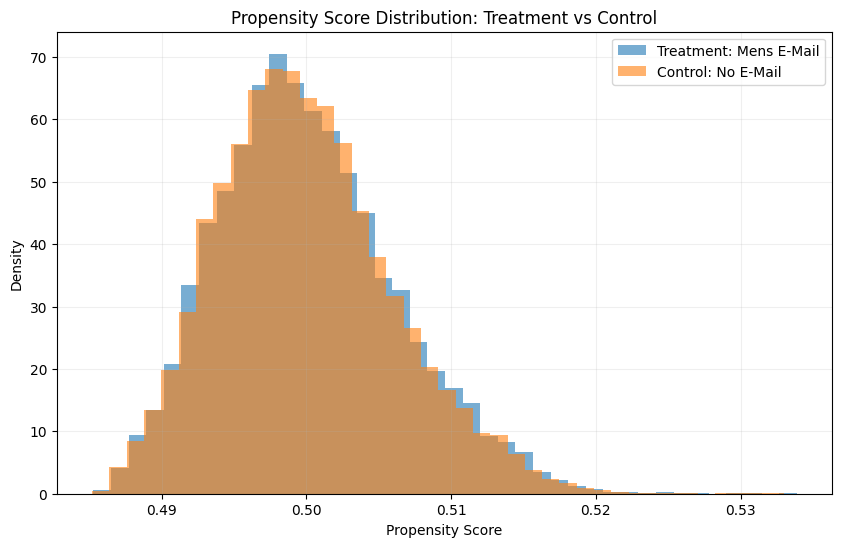

In [6]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_psm.loc[df_psm["treatment"] == 1, "propensity_score"],
    bins=40,
    alpha=0.6,
    label="Treatment: Mens E-Mail",
    density=True
)

plt.hist(
    df_psm.loc[df_psm["treatment"] == 0, "propensity_score"],
    bins=40,
    alpha=0.6,
    label="Control: No E-Mail",
    density=True
)

plt.xlabel("Propensity Score")
plt.ylabel("Density")
plt.title("Propensity Score Distribution: Treatment vs Control")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [7]:
# Step 7: Nearest Neighbour Matching

# Separate treatment and control groups
treated = df_psm[df_psm["treatment"] == 1].copy()
control = df_psm[df_psm["treatment"] == 0].copy()

# Fit nearest neighbour model on control propensity scores
nn = NearestNeighbors(n_neighbors=1, metric="euclidean")

nn.fit(control[["propensity_score"]])

# Find nearest control for every treated customer
distances, indices = nn.kneighbors(
    treated[["propensity_score"]]
)

# Apply caliper
caliper = 0.01

matched_mask = distances.flatten() <= caliper

matched_treated = treated.iloc[
    np.where(matched_mask)[0]
].copy()

matched_control = control.iloc[
    indices.flatten()[matched_mask]
].copy()

# Combine matched observations
matched_data = pd.concat(
    [matched_treated, matched_control],
    ignore_index=True
)

print("Matching completed!")
print("Original treated customers:", len(treated))
print("Original control customers:", len(control))
print("Matched pairs:", len(matched_treated))
print("Matched dataset shape:", matched_data.shape)
print("Maximum matched distance:",
      distances[matched_mask].max())

Matching completed!
Original treated customers: 21307
Original control customers: 21306
Matched pairs: 21307
Matched dataset shape: (42614, 14)
Maximum matched distance: 0.0009664593510311237


In [8]:
# Check whether control customers were reused

matched_control_indices = control.index[
    indices.flatten()[matched_mask]
]

print("Total matched control observations:",
      len(matched_control_indices))

print("Unique control customers:",
      matched_control_indices.nunique())

print("Duplicate control matches:",
      matched_control_indices.duplicated().sum())

Total matched control observations: 21307
Unique control customers: 10573
Duplicate control matches: 10734


In [10]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

# Reset matching datasets
treated_sorted = treated.copy()
control_sorted = control.copy()

# Fit nearest neighbours using control group
nn = NearestNeighbors(n_neighbors=10)
nn.fit(control_sorted[["propensity_score"]])

# Find 10 nearest controls for each treated customer
distances, indices = nn.kneighbors(
    treated_sorted[["propensity_score"]]
)

# Greedy matching without replacement
used_controls = set()
matched_pairs = []

# Sort treated customers by their nearest available distance
order = np.argsort(distances[:, 0])

for i in order:
    for k in range(10):
        j = indices[i, k]
        distance = distances[i, k]

        if distance <= caliper and j not in used_controls:
            matched_pairs.append((i, j))
            used_controls.add(j)
            break

# Create matched datasets
matched_treated = treated_sorted.iloc[
    [i for i, j in matched_pairs]
].copy()

matched_control = control_sorted.iloc[
    [j for i, j in matched_pairs]
].copy()

matched_data = pd.concat(
    [matched_treated, matched_control],
    ignore_index=True
)

print("Matching completed!")
print("Matched pairs:", len(matched_pairs))
print("Unique treated:", matched_treated.index.nunique())
print("Unique controls:", matched_control.index.nunique())
print("Duplicate controls:", matched_control.index.duplicated().sum())
print("Matched dataset shape:", matched_data.shape)

Matching completed!
Matched pairs: 17798
Unique treated: 17798
Unique controls: 17798
Duplicate controls: 0
Matched dataset shape: (35596, 14)


In [11]:
# Step 8: Calculate ATT

treated_conversion = matched_treated["conversion"].mean()
control_conversion = matched_control["conversion"].mean()

att = treated_conversion - control_conversion

print("Treatment conversion rate:", treated_conversion)
print("Control conversion rate:", control_conversion)

print("\nATT:", att)
print("ATT in percentage points:", att * 100)

Treatment conversion rate: 0.013597033374536464
Control conversion rate: 0.0060119114507248

ATT: 0.007585121923811664
ATT in percentage points: 0.7585121923811664


In [12]:
# Step 9: Covariate Balance using Standardized Mean Difference

def calculate_smd(treatment_group, control_group):
    mean_t = treatment_group.mean()
    mean_c = control_group.mean()

    var_t = treatment_group.var()
    var_c = control_group.var()

    pooled_sd = np.sqrt((var_t + var_c) / 2)

    smd = (mean_t - mean_c) / pooled_sd

    return smd


# Features used in propensity score estimation
features = X_encoded.columns.tolist()

# Before matching
before_t = X_encoded.loc[treated.index]
before_c = X_encoded.loc[control.index]

# After matching
after_t = X_encoded.loc[matched_treated.index]
after_c = X_encoded.loc[matched_control.index]

# Calculate SMD
balance_results = []

for feature in features:

    smd_before = calculate_smd(
        before_t[feature],
        before_c[feature]
    )

    smd_after = calculate_smd(
        after_t[feature],
        after_c[feature]
    )

    balance_results.append({
        "Feature": feature,
        "SMD_Before": smd_before,
        "SMD_After": smd_after,
        "Abs_SMD_Before": abs(smd_before),
        "Abs_SMD_After": abs(smd_after)
    })


balance_df = pd.DataFrame(balance_results)

print("Covariate Balance Results:")
display(balance_df.round(4))

print("\nFeatures balanced after matching:",
      (balance_df["Abs_SMD_After"] < 0.10).sum(),
      "out of", len(features))


Covariate Balance Results:


,Feature,SMD_Before,SMD_After,Abs_SMD_Before,Abs_SMD_After
0,recency,0.0068,0.0103,0.0068,0.0103
1,history,0.0076,-0.0058,0.0076,0.0058
2,mens,-0.0046,0.0000,0.0046,0.0000
3,womens,0.0076,-0.0041,0.0076,0.0041
4,newbie,-0.0009,-0.0018,0.0009,0.0018
5,zip_code_Surburban,-0.0117,-0.0046,0.0117,0.0046
6,zip_code_Urban,0.0020,0.0093,0.0020,0.0093
7,channel_Phone,-0.0083,0.0001,0.0083,0.0001
8,channel_Web,0.0110,0.0021,0.0110,0.0021



Features balanced after matching: 9 out of 9


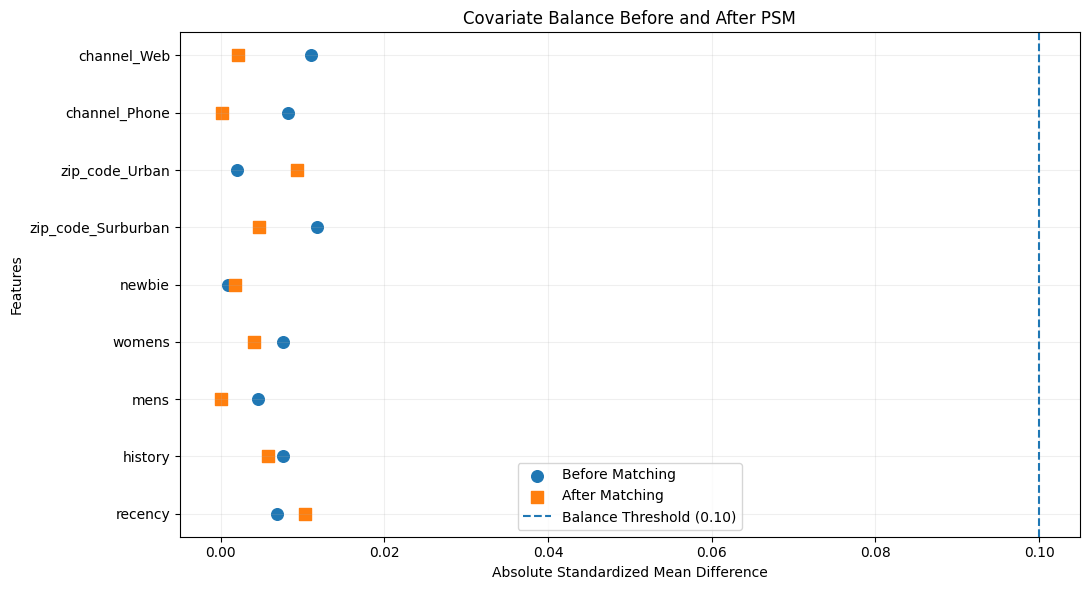

In [13]:
# Step 10: Love Plot

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

y = np.arange(len(balance_df))

plt.scatter(
    balance_df["Abs_SMD_Before"],
    y,
    label="Before Matching",
    marker="o",
    s=70
)

plt.scatter(
    balance_df["Abs_SMD_After"],
    y,
    label="After Matching",
    marker="s",
    s=70
)

plt.axvline(
    x=0.10,
    linestyle="--",
    label="Balance Threshold (0.10)"
)

plt.yticks(y, balance_df["Feature"])
plt.xlabel("Absolute Standardized Mean Difference")
plt.ylabel("Features")
plt.title("Covariate Balance Before and After PSM")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [14]:
# Save matched dataset
matched_data.to_csv(
    "section_b_psm_matched_data.csv",
    index=False
)

# Save covariate balance results
balance_df.to_csv(
    "section_b_psm_balance_results.csv",
    index=False
)

# Save ATT summary
att_results = pd.DataFrame({
    "Metric": [
        "Treatment Conversion Rate",
        "Control Conversion Rate",
        "ATT",
        "ATT Percentage Points",
        "Matched Pairs"
    ],
    "Value": [
        treated_conversion,
        control_conversion,
        att,
        att * 100,
        len(matched_pairs)
    ]
})

att_results.to_csv(
    "section_b_psm_att_results.csv",
    index=False
)

print("PSM result files saved successfully!")

PSM result files saved successfully!


In [15]:
matched_data.to_csv(
    "section_b_psm_matched_data.csv",
    index=False
)

balance_df.to_csv(
    "section_b_psm_balance_results.csv",
    index=False
)

att_results = pd.DataFrame({
    "Metric": [
        "Treatment Conversion Rate",
        "Control Conversion Rate",
        "ATT",
        "ATT Percentage Points",
        "Matched Pairs"
    ],
    "Value": [
        treated_conversion,
        control_conversion,
        att,
        att * 100,
        len(matched_pairs)
    ]
})

att_results.to_csv(
    "section_b_psm_att_results.csv",
    index=False
)

print("All PSM result files saved successfully!")

All PSM result files saved successfully!


In [16]:
from google.colab import files

files.download("section_b_psm_matched_data.csv")
files.download("section_b_psm_balance_results.csv")
files.download("section_b_psm_att_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>